# 2-D simulation vs the same plane cut out of a 3-D simulation

**Question.** If the scenario is simulated in 3-D and the traces are taken in the plane of the receivers and
shots, how different are they from a 2-D simulation of that plane?

**Setup.** Everything that is not dimensionality is made identical: texture-free rock, the same rough
wall and EDZ along the plane, receivers and shots exactly at the springline (height 0), wall-normal
hammer blows, the same grid (dx = 0.25 m) and source (500 Hz Ricker). 4 shots × 2 receivers, offsets 12-37 m.
What still differs is inherent to 2-D: a line source instead of a point source, and the tunnel as an
infinite slab instead of a cylinder.

**Comparisons.** 2-D traces as simulated, and after the standard line-to-point-source correction
(half-derivative filter, 45° phase shift). Each window is normalised before comparing, because 2-D and
3-D absolute amplitudes have different units. Measures as in notebook 01; `p` = exponent of
first-arrival amplitude decay with offset (amplitude ∝ offset^-p).

In [1]:
%matplotlib inline
import os, sys
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, ".")
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from fasim.gen.meta import load_meta
from fasim.gen.sampler import sample_draw, summary
from fasim.gen.experiments import (run_variant, compare_shapes, line_to_point, decay_exponent,
                                   fa_visibility, fa_window, nrms, table, COMP_NAMES)

OV = ["acquisition.n_receivers=2", "acquisition.receiver_spacing=5.0", "acquisition.gap=12.0",
      "acquisition.n_shots=4", "acquisition.shot_spacing=5.0", "record.length_ms=25",
      "rock.structures.count=0", "rock.texture.large.std=0", "rock.texture.small.std=0",
      "sources.impact.direction_jitter_deg=0", "acquisition.jitter_height=0", "acquisition.height=0",
      "tunnel.roughness.amplitude=0.1", "tunnel.roughness.corr_length=1.0", "tunnel.roughness.overbreak_bias=0.3",
      "tunnel.curvature.std_vertical=0", "tunnel.curvature.std_horizontal=0",
      "grid.dx_2d=0.25", "grid.dx_3d=0.25",
      "domain.depth_into_rock=15", "domain.vertical_half=10", "domain.ahead_of_face=10"]
META = load_meta(overrides=OV)
B = sample_draw(META, 11)
print(summary(B))
R = {(src, d): run_variant(B, META, dims=d, wall="bare", source=src, freq=500.0, chunk=4, label=f"{d}-D {src}")
     for src in ("impact", "explosive") for d in (2, 3)}

seed 11
tunnel  : radius 5.25 m, horizontal straight, vertical straight, face at s = 42.0 m
wall    : roughness 0.10 m rms / 1.0 m, overbreak bias 0.30; concrete 0.11 m, vp 3892
acq     : 2 receivers @ 5.00 m, gap 12.0 m, 4 shots @ 5.00 m, jitter 0.09/0.18/0.00 m, 0 virtual
sources : explosive 508 Hz, impact 1591 Hz (cone 0.0 deg)
rock    : gneiss q=0.36 vp 4836 vs 2509 Q_P 17 fabric foliated x1.9; EDZ 1.38 m x0.69
texture : large 0.000/1.1 m, small 0.000/0.31 m
  [cached] 2-D impact
  [cached] 3-D impact
  [cached] 2-D explosive
  [cached] 3-D explosive


In [2]:
def summ(rows):
    med = lambda k: float(np.median(np.abs([r[k] for r in rows])))
    return {"|dt_eik| ms": med("dt_eik"), "|dt_fa| ms": med("dt_fa"),
            "nrms_fa %": float(np.median([r["nrms_fa"] for r in rows])),
            "nrms %": float(np.median([r["nrms"] for r in rows]))}

S, EXTRA = {}, {}
for src in ("impact", "explosive"):
    r2, r3 = R[(src, 2)], R[(src, 3)]
    raw = compare_shapes(r3, r2)
    cor = compare_shapes(r3, line_to_point(r2))
    S[f"{src}: 2-D as simulated"] = summ(raw)
    S[f"{src}: 2-D corrected"] = summ(cor)
    v2, v3 = fa_visibility(r2, ("s", "n")), fa_visibility(r3, ("s", "n"))
    EXTRA[src] = {"p 2-D": decay_exponent(raw, "rms_fa_var"), "p 3-D": decay_exponent(raw, "rms_fa_ref"),
                  "vis s 2-D dB": v2["s"], "vis s 3-D dB": v3["s"], "vis n 2-D dB": v2["n"], "vis n 3-D dB": v3["n"]}
display(Markdown("**Waveform and timing difference, 2-D vs 3-D** (medians over 8 traces × components s, n)\n\n" + table(S)))
display(Markdown("**Amplitude decay exponent and first-arrival visibility**\n\n" + table(EXTRA, "{:.2f}")))
print(f"runtime per shot: 2-D {R[('impact', 2)]['seconds_per_shot']:.1f} s, 3-D {R[('impact', 3)]['seconds_per_shot']:.0f} s "
      f"({R[('impact', 3)]['cells'] / 1e6:.2f} M cells)")

**Waveform and timing difference, 2-D vs 3-D** (medians over 8 traces × components s, n)

| experiment | |dt_eik| ms | |dt_fa| ms | nrms_fa % | nrms % |
|---|---|---|---|---|
| impact: 2-D as simulated | 0.01 | 0.39 | 117.21 | 126.65 |
| impact: 2-D corrected | 0.01 | 0.04 | 74.81 | 76.51 |
| explosive: 2-D as simulated | 0.01 | 0.16 | 94.92 | 126.12 |
| explosive: 2-D corrected | 0.01 | 0.02 | 43.65 | 82.93 |

**Amplitude decay exponent and first-arrival visibility**

| experiment | p 2-D | p 3-D | vis s 2-D dB | vis s 3-D dB | vis n 2-D dB | vis n 3-D dB |
|---|---|---|---|---|---|---|
| impact | 2.59 | 3.62 | -10.94 | -12.16 | -14.36 | -16.30 |
| explosive | 1.74 | 2.23 | -1.06 | -4.04 | -15.99 | -13.74 |

runtime per shot: 2-D 0.1 s, 3-D 133 s (1.35 M cells)


## Traces: 3-D (black) vs corrected 2-D (red), each trace normalised to its first-arrival RMS

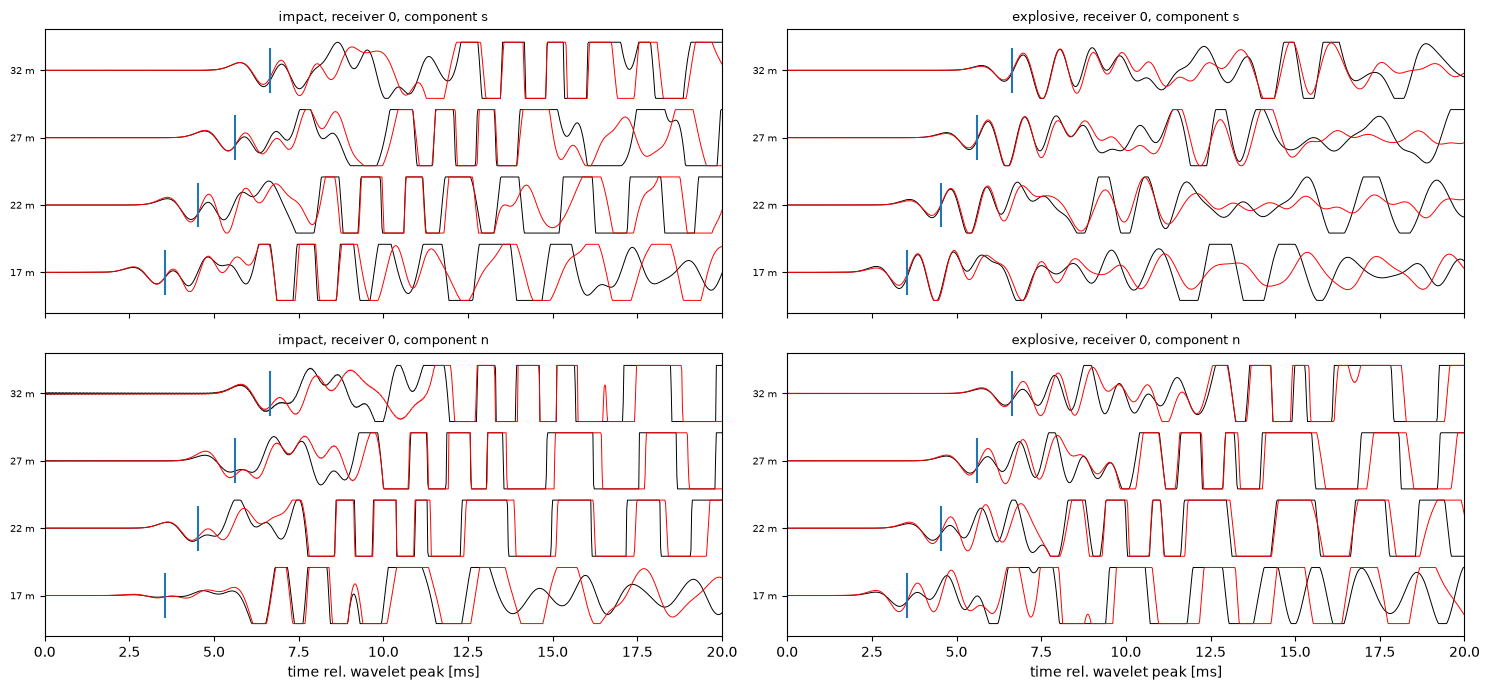

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(15, 7), sharex=True)
for j, src in enumerate(("impact", "explosive")):
    r3, r2 = R[(src, 3)], line_to_point(R[(src, 2)])
    t = r3["t"] * 1e3
    for i, comp in enumerate(("s", "n")):
        ax, ci = axes[i, j], COMP_NAMES.index(comp)
        for k in range(r3["data"].shape[0]):
            w = fa_window(r3, k, 0)
            for res, col in ((r3, "k"), (r2, "r")):
                tr = res["data"][k, 0, ci].astype(float)
                tr = tr / (np.sqrt(np.mean(tr[w] ** 2)) + 1e-30)
                ax.plot(t, 3 * k + np.clip(tr, -2.5, 2.5) * 0.5, col, lw=0.7)
            ax.vlines(r3["eik"][k, 0] * 1e3, 3 * k - 1, 3 * k + 1, colors="tab:blue")
        ax.set_title(f"{src}, receiver 0, component {comp}", fontsize=9)
        ax.set_yticks(3 * np.arange(r3["data"].shape[0]))
        ax.set_yticklabels([f"{o:.0f} m" for o in r3["offset"][:, 0]], fontsize=7)
        ax.set_xlim(0, 20)
axes[-1, 0].set_xlabel("time rel. wavelet peak [ms]"); axes[-1, 1].set_xlabel("time rel. wavelet peak [ms]")
fig.tight_layout(); plt.show()

## First-arrival amplitude vs offset (normalised at the nearest offset)

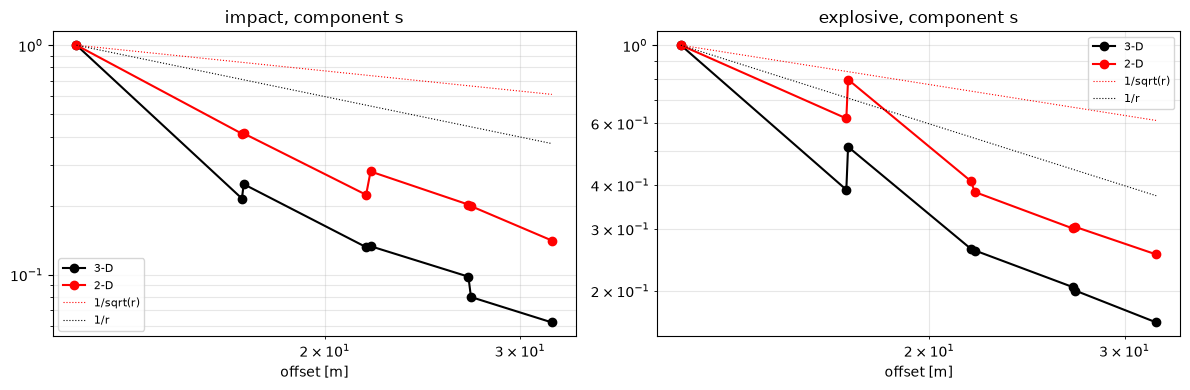

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, src in zip(axes, ("impact", "explosive")):
    rows = [r for r in compare_shapes(R[(src, 3)], R[(src, 2)]) if r["comp"] == "s"]
    off = np.array([r["offset"] for r in rows]); o = np.argsort(off)
    for key, lab, col in (("rms_fa_ref", "3-D", "k"), ("rms_fa_var", "2-D", "r")):
        a = np.array([r[key] for r in rows])[o]
        ax.loglog(off[o], a / a[0], "o-", color=col, label=lab)
    oo = np.array([off.min(), off.max()])
    ax.loglog(oo, (oo / oo[0]) ** -0.5, "r:", lw=0.8, label="1/sqrt(r)")
    ax.loglog(oo, (oo / oo[0]) ** -1.0, "k:", lw=0.8, label="1/r")
    ax.set_title(f"{src}, component s"); ax.set_xlabel("offset [m]"); ax.legend(fontsize=8); ax.grid(alpha=0.3, which="both")
fig.tight_layout(); plt.show()

## Conclusions

1. **Timing: the same.** Eikonal traveltimes differ by 0.01 ms. After the line-to-point correction the first-arrival
   waveforms line up within 0.02-0.04 ms (1-2 samples at 48 kHz).
2. **Uncorrected 2-D shifts the first arrival.** As simulated, 2-D waveforms are 0.16-0.39 ms off at the first
   arrival because of the line-source phase. The half-derivative correction removes this, so it must be applied to
   any 2-D training data.
3. **Waveform shape: first cycle close, then diverging.** After correction the first-arrival window differs by 44 %
   (explosive) and 75 % (impact); the whole trace by 77-83 %. The later phases differ because the tunnel is a
   cylinder in 3-D and an infinite slab in 2-D, which changes the wall waves.
4. **Amplitude falls faster with offset in 3-D.** The decay exponent is 0.5 (explosive) to 1.0 (impact) larger in 3-D.
   Over 12-37 m the 3-D first arrival loses an extra 1.7× (explosive) to 3× (impact) relative to 2-D. Both decay much
   faster than plain spreading, because the paths run along the free wall.
5. **Visibility.** The first arrival is 1-3 dB less visible in 3-D on component s; component n is mixed.
6. **Cost.** 0.1 s per shot in 2-D against 133 s in 3-D on the M4 CPU (1.35 M cells).

**Caveats.** Best case for 2-D: sensors and shots exactly in the plane, texture-free rock, no out-of-plane geology,
bare wall, one rock, 500 Hz, 8 traces. Out-of-plane structures, sensor heights or tilted blows would add differences
that 2-D cannot represent.
